In [ ]:
#EDA and Overview

In [ ]:
#fake-news-project/
#│
#├── data/
#│   ├── data.csv
#│   └── validation_data.csv
#│
#├── notebooks/
#│   ├── 01_eda.ipynb
#│   ├── 02_1st method_tfidf_logreg.ipynb
#│   ├── 03_2nd_metod_bow_bayes.ipynb
#│   ├── 04_tfidf_tree_models.ipynb
#│   └── 05_comparation_method_and_valdata.ipynb
#│
#├── requirements.txt
#└── README.md


# Exploratory Data Analysis – Fake News Dataset

## Objective
The goal of this notebook is to inspect and understand the training dataset before building classification models.

## Important note
Only `data.csv` is used in this notebook.
The separate validation dataset is intentionally not used at this stage.

## Data quality note
During loading, the raw CSV file showed formatting inconsistencies.
Therefore, the dataset is first reconstructed into a usable tabular format before applying NLP preprocessing and EDA.

In [ ]:
import pandas as pd
import numpy as np
import csv
import re

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 200)

# Load Dataset


In [ ]:
file_path = "/content/data.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (39942, 5)


,label,title,text,subject,date
0,1,"As U.S. budget fight looms, Republicans flip their fiscal script","WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fis...",politicsNews,"December 31, 2017"
1,1,U.S. military to accept transgender recruits on Monday: Pentagon,"WASHINGTON (Reuters) - Transgender people will be allowed for the first time to enlist in the U.S. military starting on Monday as ordered by federal courts, the Pentagon said on Friday, after Pres...",politicsNews,"December 29, 2017"
2,1,Senior U.S. Republican senator: 'Let Mr. Mueller do his job',"WASHINGTON (Reuters) - The special counsel investigation of links between Russia and President Trump’s 2016 election campaign should continue without interference in 2018, despite calls from some ...",politicsNews,"December 31, 2017"
3,1,FBI Russia probe helped by Australian diplomat tip-off: NYT,"WASHINGTON (Reuters) - Trump campaign adviser George Papadopoulos told an Australian diplomat in May 2016 that Russia had political dirt on Democratic presidential candidate Hillary Clinton, the N...",politicsNews,"December 30, 2017"
4,1,Trump wants Postal Service to charge 'much more' for Amazon shipments,"SEATTLE/WASHINGTON (Reuters) - President Donald Trump called on the U.S. Postal Service on Friday to charge “much more” to ship packages for Amazon (AMZN.O), picking another fight with an online r...",politicsNews,"December 29, 2017"


The dataset contains several columns:

- label → indicates whether the news is fake or real
- title → headline of the article
- text → full article content
- subject → topic category
- date → publication date

Next, we inspect the dataset structure.


## Dataset Structure

We inspect the dataset structure to understand:

- number of observations
- available columns
- data types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39942 entries, 0 to 39941
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    39942 non-null  int64 
 1   title    39942 non-null  object
 2   text     39942 non-null  object
 3   subject  39942 non-null  object
 4   date     39942 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.5+ MB


## Missing Values

Missing values can cause problems during model training.
Therefore we check whether any columns contain missing data.

In [ ]:
df.isnull().sum()


,0
label,0
title,0
text,0
subject,0
date,0


## Class Distribution

Before training a classification model, it is important to understand
how the target variable is distributed.

If one class strongly dominates the dataset,
the model might simply learn to predict that class.

Therefore we visualize how many fake and real news articles exist.

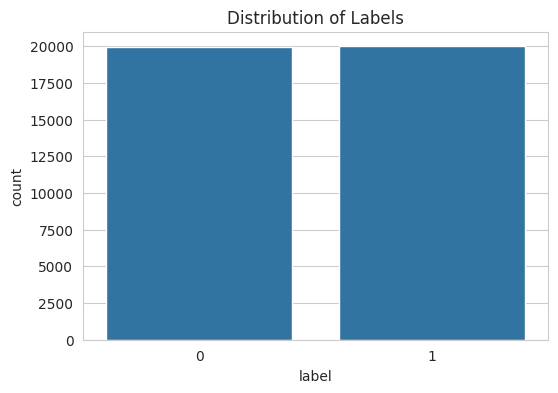

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="label")

plt.title("Distribution of Labels")

plt.show()

In [ ]:
label_map = {0: "Real", 1: "Fake"}

df["label_name"] = df["label"].map(label_map)

df["label_name"].value_counts()

,count
label_name,
Fake,19999
Real,19943


# Interpretation

The dataset appears relatively balanced between fake and real news.

This is beneficial for training a classification model because
the model will not be biased toward predicting one class more often.

## Text Length Analysis

Fake and real news articles may differ in writing style and length.

Therefore we analyze the distribution of article lengths.
This may reveal structural differences between the two classes.

In [ ]:
df["text_length"] = df["text"].apply(len)
df["title_length"] = df["title"].apply(len)

df[["text_length","title_length"]].describe()

,text_length,title_length
count,39942.000000,39942.000000
mean,2384.637875,79.774723
std,1765.895463,24.811136
min,1.000000,8.000000
25%,1259.000000,63.000000
50%,2197.000000,73.000000
75%,3069.000000,90.000000
max,49705.000000,286.000000


To better understand the distribution of article lengths,
we visualize the text length using a histogram.

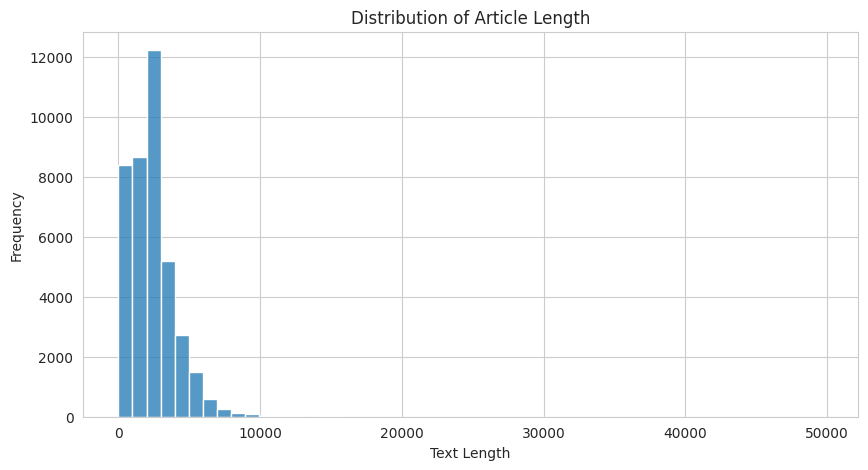

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df["text_length"], bins=50)

plt.title("Distribution of Article Length")
plt.xlabel("Text Length")
plt.ylabel("Frequency")

plt.show()

Next we compare the article length between fake and real news.
This may reveal whether one class tends to contain longer or shorter articles.

## Word Frequency Analysis

Before building models, we inspect the most common words
in the dataset.

This helps us understand common vocabulary and potential
dataset biases.

In [ ]:
import re

def clean_text(text):

    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text

df["clean_text"] = (df["title"] + " " + df["text"]).apply(clean_text)

In [ ]:
from collections import Counter

all_words = " ".join(df["clean_text"]).split()

word_freq = Counter(all_words)

common_words = word_freq.most_common(20)

words_df = pd.DataFrame(common_words, columns=["word","count"])

words_df

,word,count
0,the,877542
1,to,481025
2,of,380301
3,a,362761
4,and,350838
5,in,309305
6,s,266413
7,that,210457
8,on,175436
9,for,157788


### Removing Stopwords

In the previous visualization, many of the most frequent words were common
English stopwords such as "the", "is", and "and".

These words appear very frequently in natural language but usually carry
little semantic meaning for classification tasks.

Therefore we remove stopwords to better reveal the informative vocabulary
in the dataset.

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stopwords = set(ENGLISH_STOP_WORDS)

len(stopwords)

318

In [ ]:
filtered_words = [
    word for word in all_words
    if word not in stopwords and len(word) > 2
]

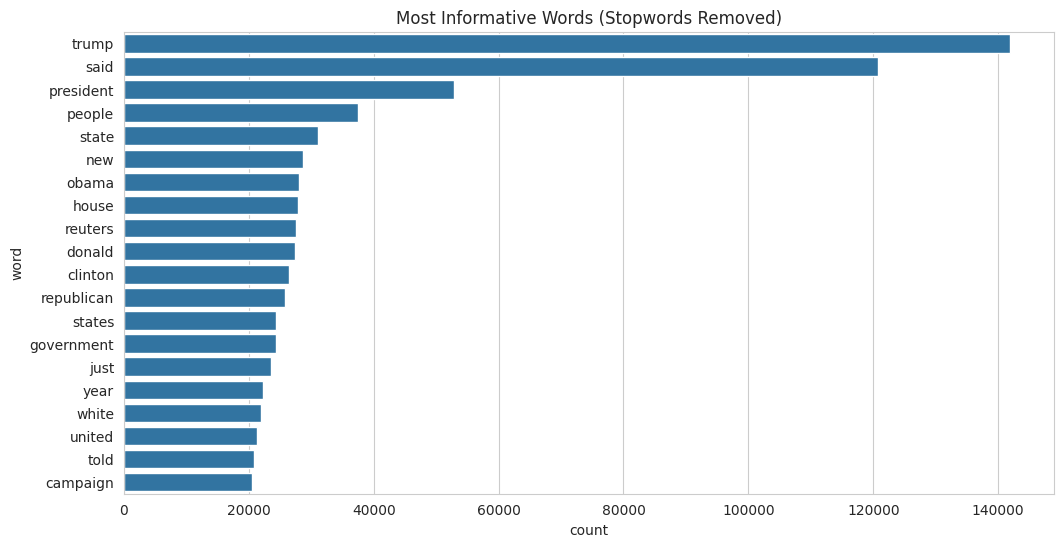

In [ ]:
filtered_freq = Counter(filtered_words)

filtered_common = filtered_freq.most_common(20)

filtered_df = pd.DataFrame(filtered_common, columns=["word","count"])

plt.figure(figsize=(12,6))

sns.barplot(data=filtered_df, x="count", y="word")

plt.title("Most Informative Words (Stopwords Removed)")

plt.show()


# Bigram Analysis

Single words can lose context. Therefore we also analyze bigrams
(two-word combinations) to identify common phrases.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2,2),
    max_features=20
)

X = vectorizer.fit_transform(df["clean_text"])

bigrams = vectorizer.get_feature_names_out()

counts = X.toarray().sum(axis=0)

bigram_df = pd.DataFrame({
    "bigram": bigrams,
    "count": counts
}).sort_values("count", ascending=False)

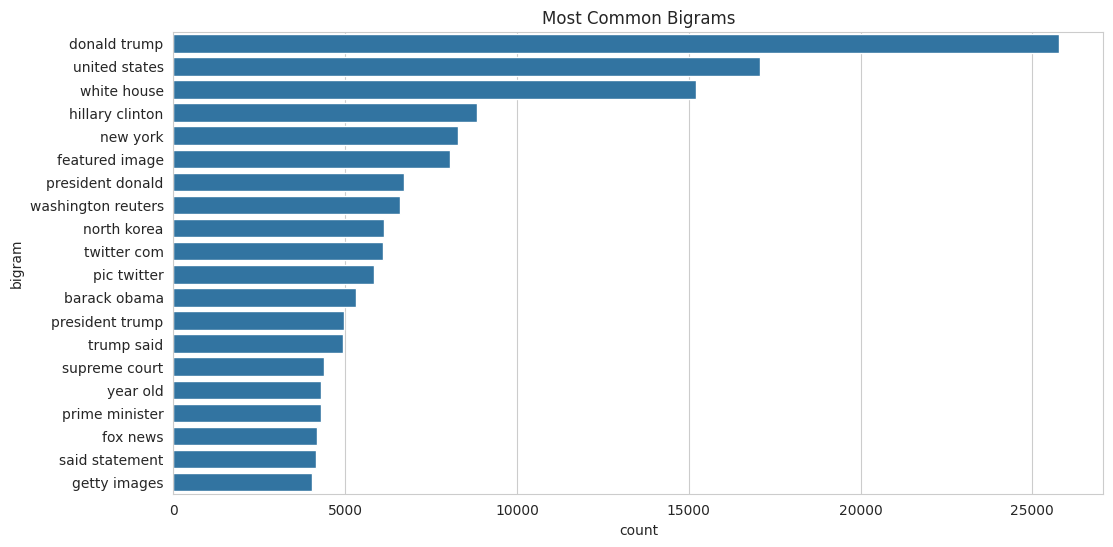

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(data=bigram_df, x="count", y="bigram")

plt.title("Most Common Bigrams")

plt.show()

The bigram analysis reveals common phrases in the dataset,
such as political entities or locations.

These phrases may contain more semantic information than
individual words and could improve model performance.

#Trigram Analysis

While bigrams capture two-word combinations, trigrams capture
three-word sequences.

These may contain even more context and may represent common
phrases in political news articles.

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(3,3),
    max_features=20
)

X = vectorizer.fit_transform(df["clean_text"])

trigrams = vectorizer.get_feature_names_out()

counts = X.sum(axis=0).A1

trigram_df = pd.DataFrame({
    "trigram": trigrams,
    "count": counts
}).sort_values("count", ascending=False)

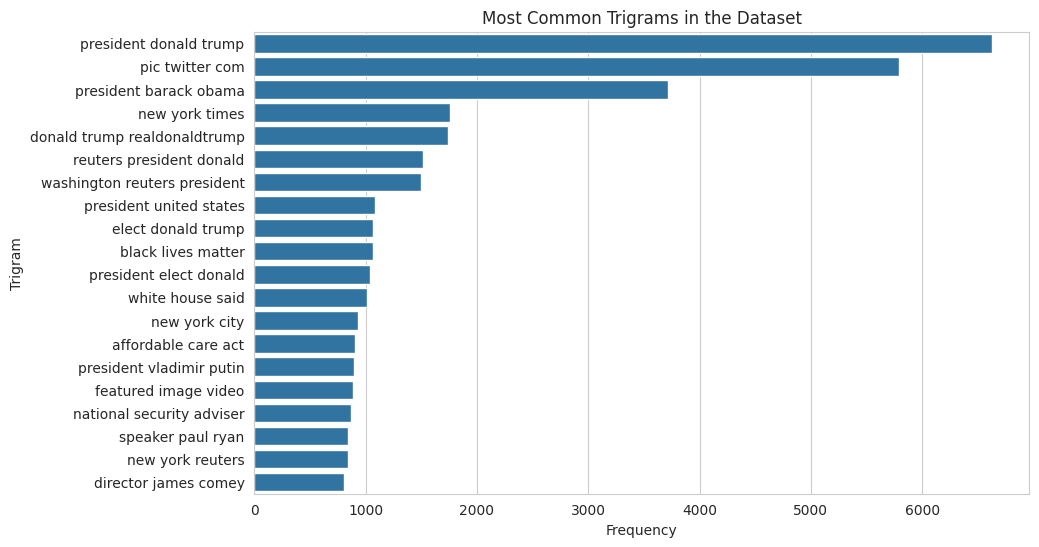

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(data=trigram_df, x="count", y="trigram")

plt.title("Most Common Trigrams in the Dataset")
plt.xlabel("Frequency")
plt.ylabel("Trigram")

plt.show()

## Unigram + Bigram Analysis

Instead of analyzing single words or bigrams separately,
we can combine both representations.

This allows the model to use both individual words and
two-word phrases as features.

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1,2),
    max_features=20
)

X = vectorizer.fit_transform(df["clean_text"])

ngrams = vectorizer.get_feature_names_out()

counts = X.sum(axis=0).A1

ngram_df = pd.DataFrame({
    "ngram": ngrams,
    "count": counts
}).sort_values("count", ascending=False)

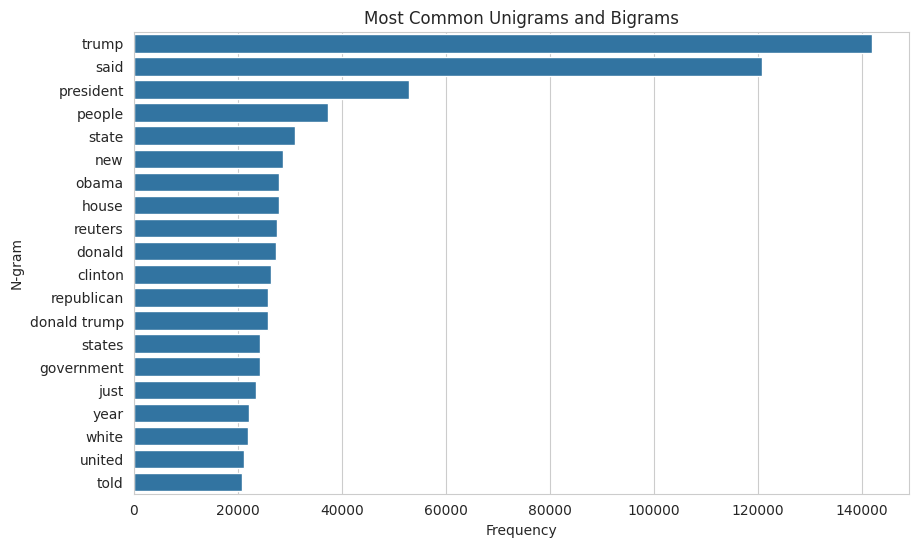

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(data=ngram_df, x="count", y="ngram")

plt.title("Most Common Unigrams and Bigrams")
plt.xlabel("Frequency")
plt.ylabel("N-gram")

plt.show()

#Prepare data for vectorization

In [ ]:
import nltk
nltk.download(['punkt_tab', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'universal_tagset'], quiet=True)

True

In [ ]:
import nltk
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

True

In [ ]:

from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import wordnet
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# 1. Tokenization(NLTK)
tokenized = [word_tokenize(doc.lower()) for doc in filtered_words]

# 2. Lematization
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    """Convierts tag de NLTK to WordNet format"""
    return {'J': wordnet.ADJ, 'N': wordnet.NOUN,
            'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemmatize_document(doc):
    """Lemmatize a whole doc (faster)"""
    tagged = nltk.pos_tag(doc)             #branding all document
    lemmatized = []
    for word, tag in tagged:
        pos = get_wordnet_pos(tag)
        lemma = lemmatizer.lemmatize(word, pos)
        lemmatized.append(lemma)
    return lemmatized

# Aply lemmatization
lemma_words = [lemmatize_document(doc) for doc in tokenized]

print(" Lemmatization complete. Examples:")
print(lemma_words[0][:15])

# 3. Reconstruct clean test for Keras
cleaned_texts = [' '.join(doc) for doc in lemma_words]

# 4. Numeric tokenazation (Keras)
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(cleaned_texts)
sequences = tokenizer.texts_to_sequences(cleaned_texts)
#Padding the inputs for the model in order to have same lenght
max_seq_len = max(len(seq) for seq in sequences)
padded = pad_sequences(sequences, maxlen=max_seq_len, padding='pre')

print(f"\n Padding ended. Final shape: {padded.shape}")


#1st method

In [ ]:
from sklearn.model_selection import train_test_split
# Train–Test Split
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
# TF-IDF Vectorization with N-grams
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1,2),
    max_df=0.8,
    min_df=5
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF train shape:", X_train_tfidf.shape)

TF-IDF train shape: (31953, 214877)


## Training the Logistic Regression Model

In this step, we train a **Logistic Regression classifier** on the TF-IDF features.

Logistic Regression is a commonly used baseline model for text classification tasks. It works well with high-dimensional sparse data such as TF-IDF vectors.

The model learns weights for each word feature, allowing it to estimate the probability that a given article belongs to the fake or real news class.

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
## Generating Predictions

# After training the model, we use it to generate predictions for the test dataset.

# The model takes the TF-IDF representation of each article and predicts whether the news article is **fake or real** based on the patterns it learned during training.

In [ ]:
y_pred = model.predict(X_test_tfidf)

## Model Evaluation

To evaluate the performance of the classifier, we compute the **accuracy score** and a **classification report**.

Accuracy measures the proportion of correct predictions.

The classification report provides additional metrics such as:
- Precision
- Recall
- F1-score

These metrics help us understand how well the model performs for each class.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9847290023782701
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3989
           1       0.98      0.99      0.98      4000

    accuracy                           0.98      7989
   macro avg       0.98      0.98      0.98      7989
weighted avg       0.98      0.98      0.98      7989



## Confusion Matrix Visualization

A confusion matrix provides a detailed overview of the model’s predictions.

It shows how many examples were correctly or incorrectly classified for each class.

The matrix helps us identify common types of errors, such as fake news being classified as real or vice versa.

Visualizing the confusion matrix makes it easier to interpret the model’s performance.

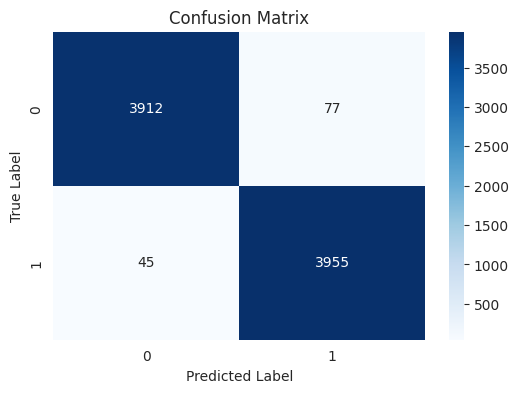

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
## Interpreting Important Words

# One advantage of Logistic Regression is that the model is interpretable.

# Each word feature receives a coefficient that indicates how strongly it contributes to predicting a class.

# By examining the highest and lowest coefficients, we can identify words that are most strongly associated with **fake news** or **real news**.

# This visualization helps us better understand how the model makes its decisions.

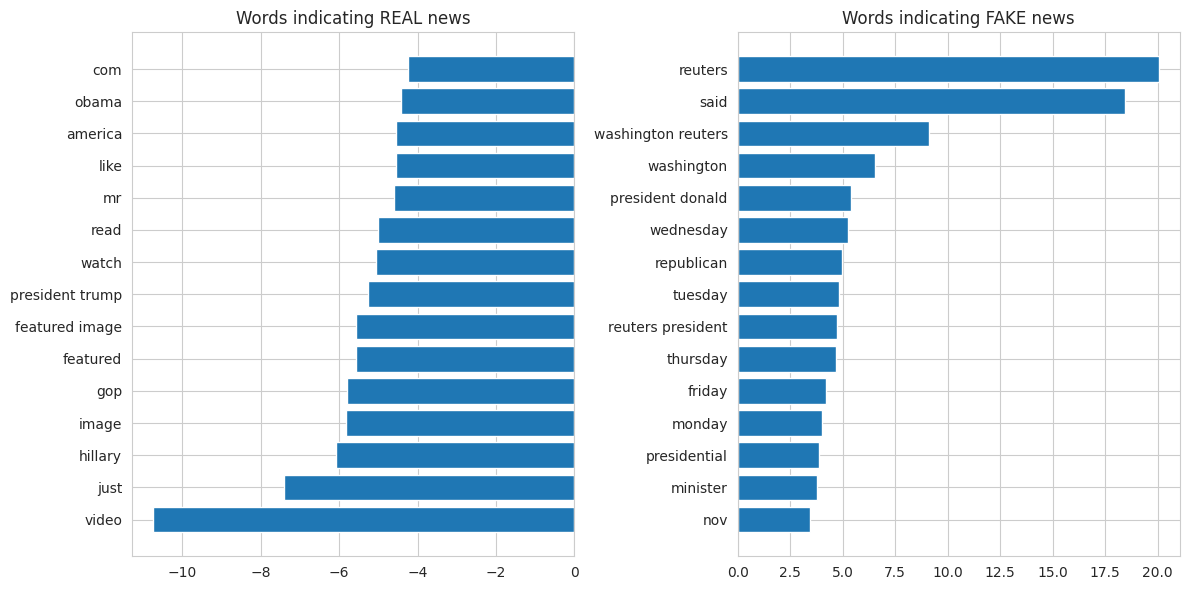

In [ ]:
import numpy as np

feature_names = tfidf.get_feature_names_out()
coefficients = model.coef_[0]

top_fake = np.argsort(coefficients)[-15:]
top_real = np.argsort(coefficients)[:15]

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.barh(feature_names[top_real], coefficients[top_real])
plt.title("Words indicating REAL news")

plt.subplot(1,2,2)
plt.barh(feature_names[top_fake], coefficients[top_fake])
plt.title("Words indicating FAKE news")

plt.tight_layout()
plt.show()

## Conclusion

In this project, we built a machine learning pipeline to classify news articles as **fake or real**.

After preprocessing the text, we converted it into numerical features using **TF-IDF with unigrams and bigrams**. We then trained a **Logistic Regression model** on these features.

The evaluation results show that the model can effectively distinguish between fake and real news. Additionally, analyzing the model’s coefficients helps us understand which words contribute most to the predictions.

#2method

## Bag of Words + Naive Bayes

As a baseline model, we use a Bag of Words representation
combined with a Naive Bayes classifier.

Bag of Words represents each document by the frequency
of its words without considering word order.

Accuracy: 0.9439228939792215
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      3989
           1       0.95      0.94      0.94      4000

    accuracy                           0.94      7989
   macro avg       0.94      0.94      0.94      7989
weighted avg       0.94      0.94      0.94      7989



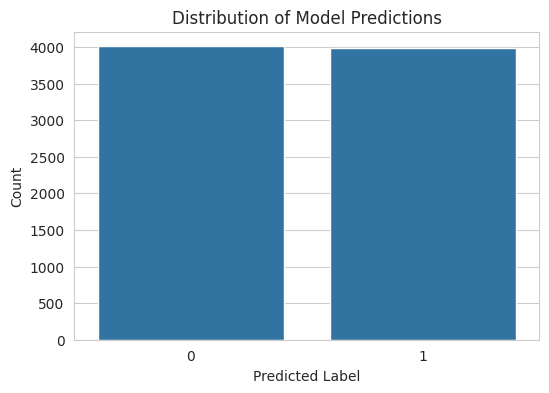

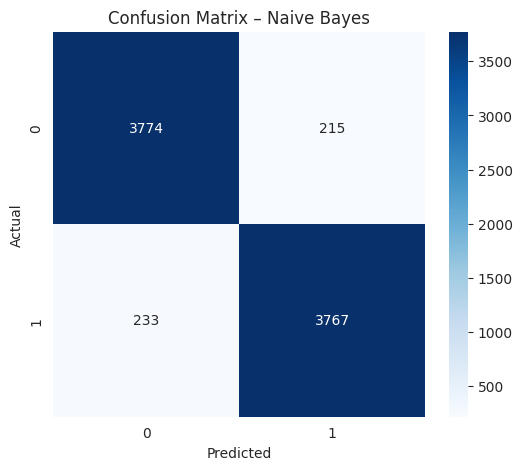

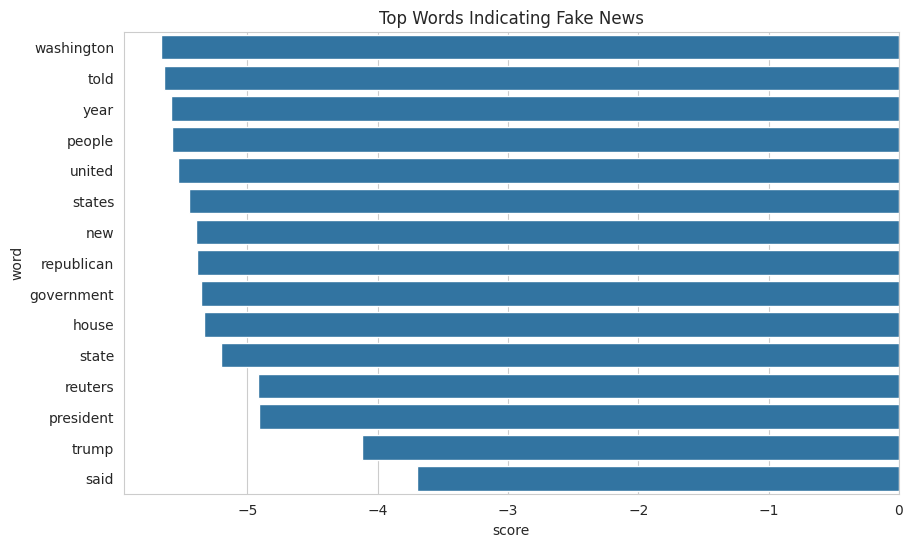

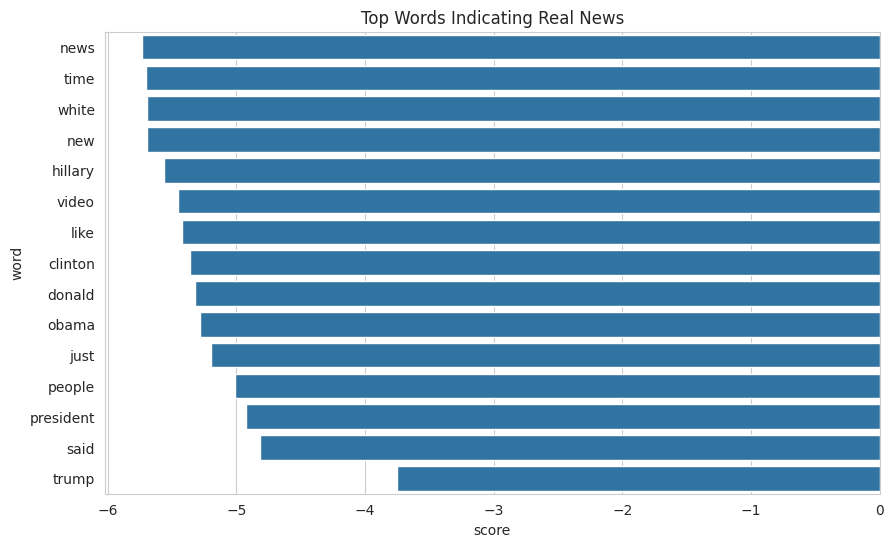

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt


#Feature Extraction – Bag of Words

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1,1),  # nur Unigrams
    max_features=5000
)

X = vectorizer.fit_transform(df["clean_text"])

y = df["label"]


#Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

#Modell trainieren

model = MultinomialNB()

model.fit(X_train, y_train)

#Predictions

y_pred = model.predict(X_test)

#Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)



#Classification Report

print(classification_report(y_test, y_pred))

#Visualization
#Prediction Distribution

import pandas as pd

pred_df = pd.DataFrame({
    "prediction": y_pred
})

plt.figure(figsize=(6,4))

sns.countplot(data=pred_df, x="prediction")

plt.title("Distribution of Model Predictions")
plt.xlabel("Predicted Label")
plt.ylabel("Count")

plt.show()





#Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Naive Bayes")

plt.show()





#Top Words Learned by Naive Bayes

import numpy as np

feature_names = vectorizer.get_feature_names_out()

log_probs = model.feature_log_prob_

fake_top = np.argsort(log_probs[1])[-15:]

fake_words = [feature_names[i] for i in fake_top]

fake_scores = log_probs[1][fake_top]

fake_df = pd.DataFrame({
    "word": fake_words,
    "score": fake_scores
})



#Top Words Indicating Fake News

plt.figure(figsize=(10,6))

sns.barplot(data=fake_df, x="score", y="word")

plt.title("Top Words Indicating Fake News")

plt.show()



#Top Words Indicating Real News

real_top = np.argsort(log_probs[0])[-15:]

real_words = [feature_names[i] for i in real_top]

real_scores = log_probs[0][real_top]

real_df = pd.DataFrame({
    "word": real_words,
    "score": real_scores
})

plt.figure(figsize=(10,6))

sns.barplot(data=real_df, x="score", y="word")

plt.title("Top Words Indicating Real News")

plt.show()

### Interpretation

The Naive Bayes classifier provides a strong baseline for
text classification tasks.

Because the model assumes independence between words,
it works particularly well with Bag of Words representations.

The performance of this model will be compared with
the TF-IDF + Logistic Regression model.

#3 method

✅ Matriz TF-IDF creada: (39942, 10000) (documentos x palabras)
=== RESULTADOS DEL MODELO ===
Accuracy: 0.9989

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3989
           1       1.00      1.00      1.00      4000

    accuracy                           1.00      7989
   macro avg       1.00      1.00      1.00      7989
weighted avg       1.00      1.00      1.00      7989



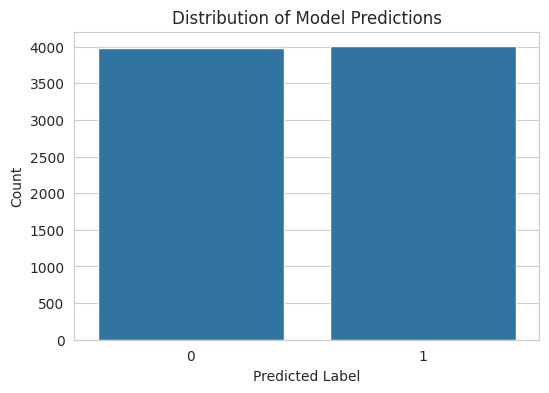

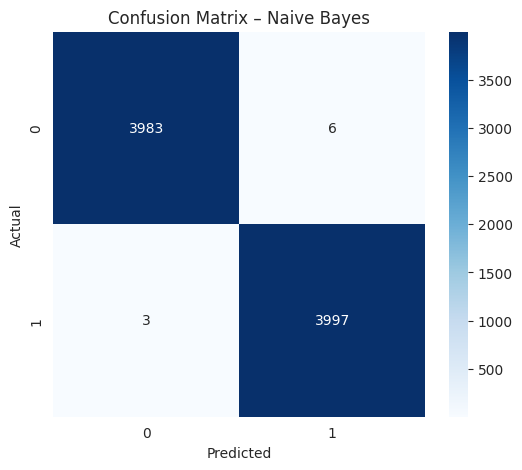

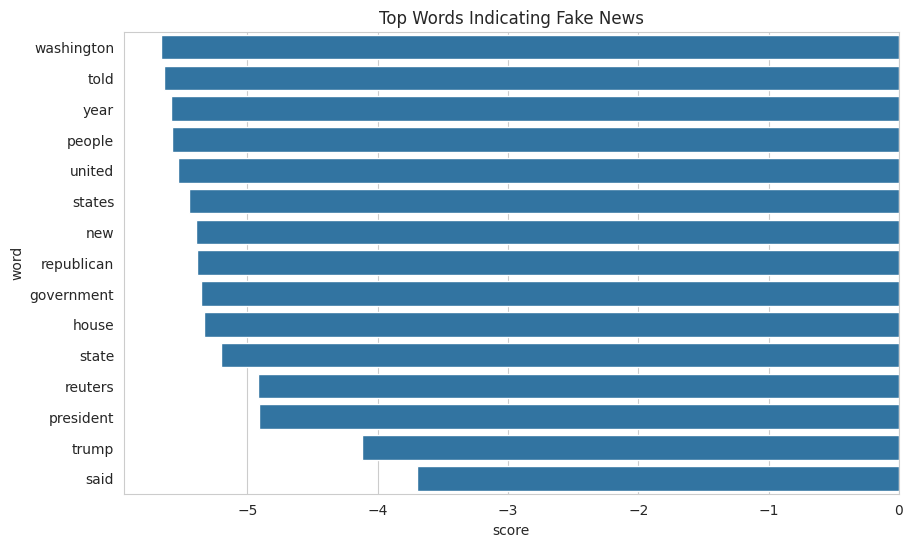

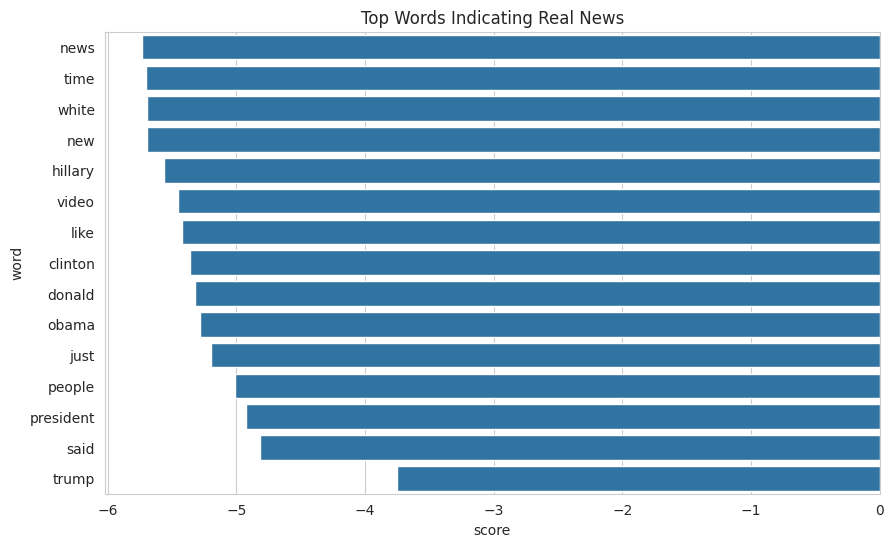

In [ ]:
# === 1. IMPORTS (agrega esto al final de tus celdas anteriores) ===
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np

# === 2. PREPARACIÓN (usa lo que ya tienes) ===
# cleaned_texts ya lo creamos en el código anterior:
# cleaned_texts = [' '.join(doc) for doc in lemma_words]

 # ← REEMPLAZA esto con tus labels reales

# === 3. TF-IDF (la parte más importante) ===
tfidf = TfidfVectorizer(
    max_features=10000,      # ajusta según tu vocabulario (5000-20000)
    ngram_range=(1, 2),      # unigrams + bigrams (mejora mucho el resultado)
    min_df=2,                # ignora palabras que aparecen en menos de 2 docs
    max_df=0.95,             # ignora palabras que aparecen en más del 95% de docs
    stop_words='english'  # cambia si es español
)

X = tfidf.fit_transform((df["clean_text"]))
y=df["label"]
print(f"✅ Matriz TF-IDF creada: {X.shape} (documentos x palabras)")

# === 4. DIVIDIR TRAIN / TEST ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# === 5. ENTRENAR Random Forest ===
rf_model = RandomForestClassifier(
    n_estimators=200,      # más árboles = mejor (pero más lento)
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1              # usa todos los núcleos de tu CPU
)

rf_model.fit(X_train, y_train)

# === 6. PREDICCIONES Y RESULTADOS ===
y_pred = rf_model.predict(X_test)

print("=== RESULTADOS DEL MODELO ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

#Visualization
#Prediction Distribution

import pandas as pd

pred_df = pd.DataFrame({
    "prediction": y_pred
})

plt.figure(figsize=(6,4))

sns.countplot(data=pred_df, x="prediction")

plt.title("Distribution of Model Predictions")
plt.xlabel("Predicted Label")
plt.ylabel("Count")

plt.show()





#Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Naive Bayes")

plt.show()





#Top Words Learned by Naive Bayes

import numpy as np

feature_names = vectorizer.get_feature_names_out()

log_probs = model.feature_log_prob_

fake_top = np.argsort(log_probs[1])[-15:]

fake_words = [feature_names[i] for i in fake_top]

fake_scores = log_probs[1][fake_top]

fake_df = pd.DataFrame({
    "word": fake_words,
    "score": fake_scores
})



#Top Words Indicating Fake News

plt.figure(figsize=(10,6))

sns.barplot(data=fake_df, x="score", y="word")

plt.title("Top Words Indicating Fake News")

plt.show()



#Top Words Indicating Real News

real_top = np.argsort(log_probs[0])[-15:]

real_words = [feature_names[i] for i in real_top]

real_scores = log_probs[0][real_top]

real_df = pd.DataFrame({
    "word": real_words,
    "score": real_scores
})

plt.figure(figsize=(10,6))

sns.barplot(data=real_df, x="score", y="word")

plt.title("Top Words Indicating Real News")

plt.show()